In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import joblib

In [99]:
df = pd.read_csv("kawempe_synthetic_admission_dataset.csv")

In [100]:
df.head()

,Patient_ID,Age,Sex,Department,Arrival_Mode,Triage_Level,Symptom_Duration_Days,Temperature_C,Pulse_bpm,SpO2_percent,Systolic_BP,Known_Comorbidity,Admission_Status
0,SYN0001,8,Male,Maternity,Referral,Yellow,9,37.2,144,96,95,No,1
1,SYN0002,70,Male,Paediatrics,Walk-in,Yellow,10,36.7,84,84,107,No,0
2,SYN0003,59,Male,Maternity,Ambulance,Green,4,36.3,68,95,103,No,1
3,SYN0004,39,Male,Maternity,Referral,Yellow,5,36.1,74,84,77,Yes,1
4,SYN0005,39,Female,Emergency,Walk-in,Green,14,37.1,67,92,76,No,0


In [101]:
df.tail()

,Patient_ID,Age,Sex,Department,Arrival_Mode,Triage_Level,Symptom_Duration_Days,Temperature_C,Pulse_bpm,SpO2_percent,Systolic_BP,Known_Comorbidity,Admission_Status
995,SYN0996,56,Female,General,Walk-in,Green,7,36.0,139,85,126,No,1
996,SYN0997,47,Male,Paediatrics,Referral,Green,3,35.8,67,83,138,Yes,0
997,SYN0998,32,Male,Paediatrics,Walk-in,Green,12,36.4,135,88,85,No,0
998,SYN0999,87,Female,General,Ambulance,Green,1,37.3,65,84,97,No,1
999,SYN1000,46,Female,Emergency,Walk-in,Green,11,37.6,138,99,130,No,0


In [102]:
df.shape

(1000, 13)

In [103]:
df.columns

Index(['Patient_ID', 'Age', 'Sex', 'Department', 'Arrival_Mode',
       'Triage_Level', 'Symptom_Duration_Days', 'Temperature_C', 'Pulse_bpm',
       'SpO2_percent', 'Systolic_BP', 'Known_Comorbidity', 'Admission_Status'],
      dtype='object')

In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Patient_ID             1000 non-null   object 
 1   Age                    1000 non-null   int64  
 2   Sex                    1000 non-null   object 
 3   Department             1000 non-null   object 
 4   Arrival_Mode           1000 non-null   object 
 5   Triage_Level           1000 non-null   object 
 6   Symptom_Duration_Days  1000 non-null   int64  
 7   Temperature_C          1000 non-null   float64
 8   Pulse_bpm              1000 non-null   int64  
 9   SpO2_percent           1000 non-null   int64  
 10  Systolic_BP            1000 non-null   int64  
 11  Known_Comorbidity      1000 non-null   object 
 12  Admission_Status       1000 non-null   int64  
dtypes: float64(1), int64(6), object(6)
memory usage: 101.7+ KB


In [105]:
df.describe()

,Age,Symptom_Duration_Days,Temperature_C,Pulse_bpm,SpO2_percent,Systolic_BP,Admission_Status
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,45.276000,7.04500,37.086200,103.958000,90.196000,127.082000,0.551000
std,26.279849,4.27519,0.800231,27.394867,5.233256,30.487321,0.497641
min,0.000000,0.00000,34.600000,55.000000,82.000000,75.000000,0.000000
25%,22.000000,3.00000,36.500000,80.000000,86.000000,102.000000,0.000000
50%,46.000000,7.00000,37.100000,106.000000,90.000000,128.000000,1.000000
75%,68.250000,11.00000,37.600000,127.000000,95.000000,153.000000,1.000000
max,90.000000,14.00000,39.700000,150.000000,99.000000,180.000000,1.000000


In [106]:
df["Admission_Status"].value_counts()

Admission_Status
1    551
0    449
Name: count, dtype: int64

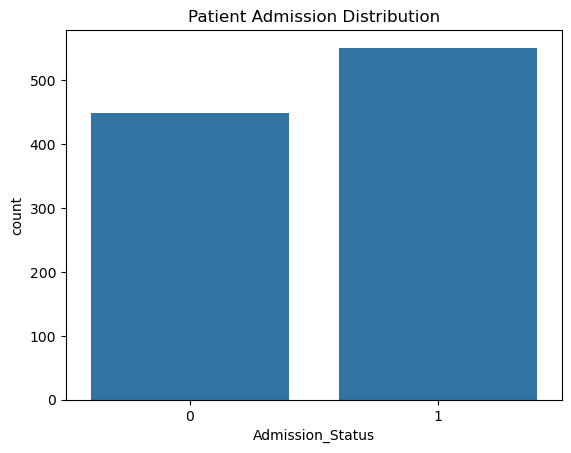

In [107]:
sns.countplot(data=df, x="Admission_Status")
plt.title("Patient Admission Distribution")
plt.show()

In [108]:
df.isnull().sum()

Patient_ID               0
Age                      0
Sex                      0
Department               0
Arrival_Mode             0
Triage_Level             0
Symptom_Duration_Days    0
Temperature_C            0
Pulse_bpm                0
SpO2_percent             0
Systolic_BP              0
Known_Comorbidity        0
Admission_Status         0
dtype: int64

In [109]:
(df.isnull().sum() / len(df)) * 100

Patient_ID               0.0
Age                      0.0
Sex                      0.0
Department               0.0
Arrival_Mode             0.0
Triage_Level             0.0
Symptom_Duration_Days    0.0
Temperature_C            0.0
Pulse_bpm                0.0
SpO2_percent             0.0
Systolic_BP              0.0
Known_Comorbidity        0.0
Admission_Status         0.0
dtype: float64

In [110]:
df.duplicated().sum()

np.int64(0)

In [111]:
df = df.drop_duplicates()

In [112]:
df = df.drop("Patient_ID", axis=1)

In [113]:
df["Admission_Status"].value_counts(normalize=True) * 100

Admission_Status
1    55.1
0    44.9
Name: proportion, dtype: float64

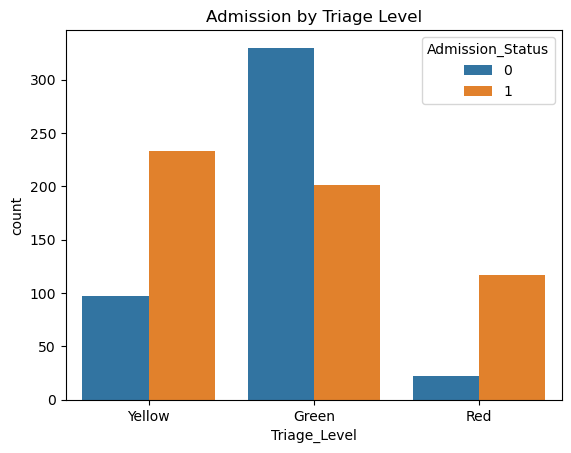

In [114]:
sns.countplot(
    data=df,
    x="Triage_Level",
    hue="Admission_Status"
)

plt.title("Admission by Triage Level")
plt.show()

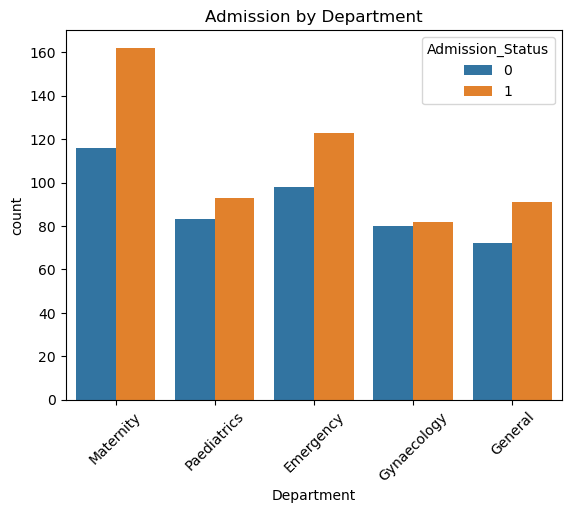

In [115]:
sns.countplot(
    data=df,
    x="Department",
    hue="Admission_Status"
)

plt.xticks(rotation=45)
plt.title("Admission by Department")
plt.show()

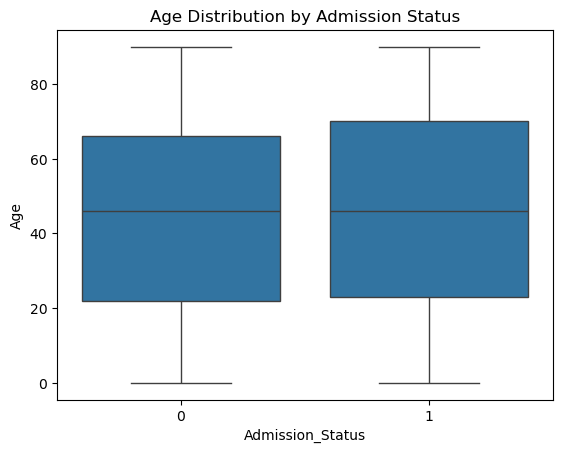

In [116]:
sns.boxplot(
    data=df,
    x="Admission_Status",
    y="Age"
)

plt.title("Age Distribution by Admission Status")
plt.show()

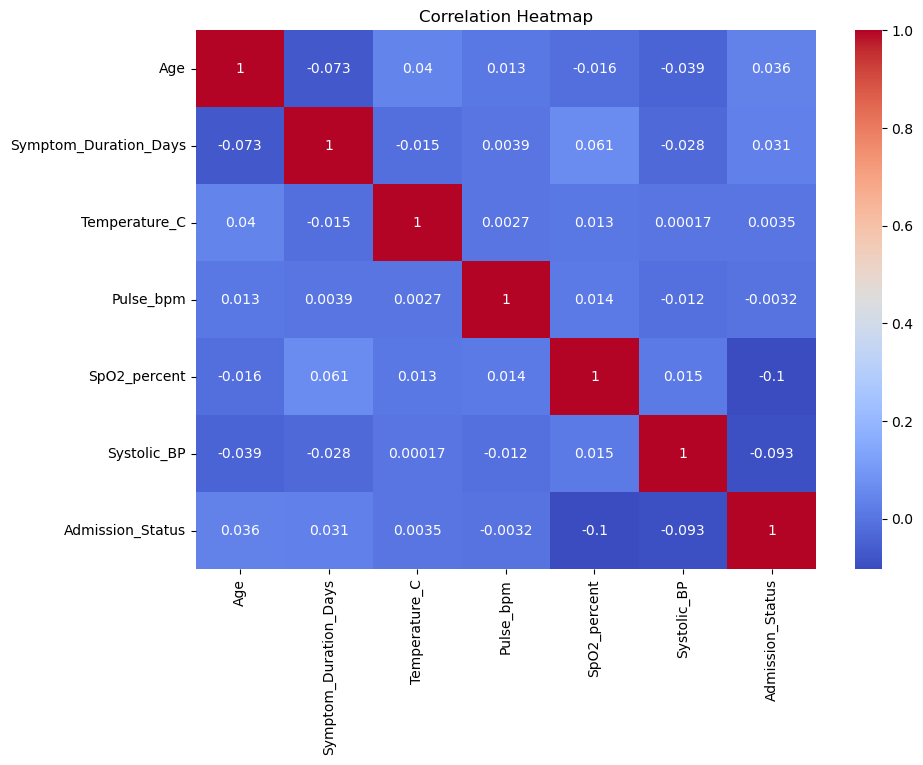

In [117]:
numeric_df = df.select_dtypes(include="number")

corr = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [118]:
X = df.drop("Admission_Status", axis=1)

y = df["Admission_Status"]

In [119]:
X.head()

,Age,Sex,Department,Arrival_Mode,Triage_Level,Symptom_Duration_Days,Temperature_C,Pulse_bpm,SpO2_percent,Systolic_BP,Known_Comorbidity
0,8,Male,Maternity,Referral,Yellow,9,37.2,144,96,95,No
1,70,Male,Paediatrics,Walk-in,Yellow,10,36.7,84,84,107,No
2,59,Male,Maternity,Ambulance,Green,4,36.3,68,95,103,No
3,39,Male,Maternity,Referral,Yellow,5,36.1,74,84,77,Yes
4,39,Female,Emergency,Walk-in,Green,14,37.1,67,92,76,No


In [120]:
y.head()

0    1
1    0
2    1
3    1
4    0
Name: Admission_Status, dtype: int64

In [121]:
categorical_features = [
    "Sex",
    "Department",
    "Arrival_Mode",
    "Triage_Level",
    "Known_Comorbidity"
]

numerical_features = [
    "Age",
    "Symptom_Duration_Days",
    "Temperature_C",
    "Pulse_bpm",
    "SpO2_percent",
    "Systolic_BP"
]

In [122]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),

        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

In [123]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [124]:
print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

Training data: (800, 11)
Testing data: (200, 11)


In [125]:
model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", LogisticRegression(
        max_iter=1000,
        C=1.0
    ))
])

In [126]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age',
                                                   'Symptom_Duration_Days',
                                                   'Temperature_C', 'Pulse_bpm',
                                                   'SpO2_percent',
                                                   'Systolic_BP']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Sex', 'Department',
                                                   'Arrival_Mode',
                                                   'Triage_Level',
                                                   'Known_Comorbidity'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [127]:
y_pred = model.predict(X_test)

In [128]:
predictions = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

predictions.head(10)

,Actual,Predicted
812,1,1
985,1,0
399,1,1
285,1,1
814,0,0
291,0,1
84,1,1
931,1,1
48,0,1
436,0,0


In [129]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.72


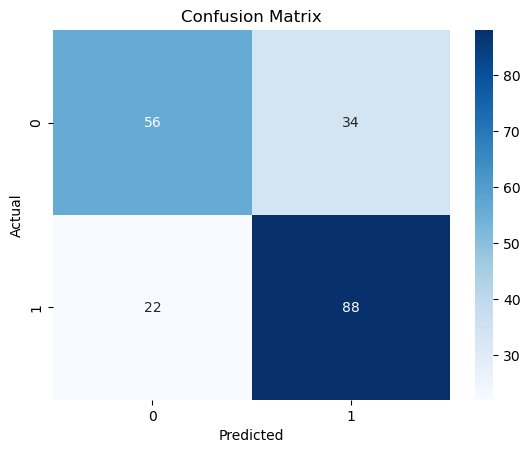

In [130]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Confusion Matrix")
plt.show()

In [131]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.72      0.62      0.67        90
           1       0.72      0.80      0.76       110

    accuracy                           0.72       200
   macro avg       0.72      0.71      0.71       200
weighted avg       0.72      0.72      0.72       200



In [132]:
y_prob = model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", auc)

ROC-AUC: 0.7333333333333334


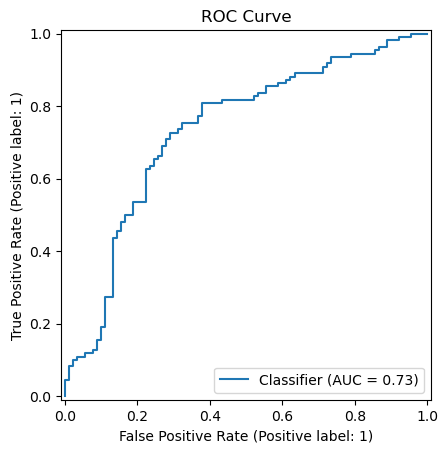

In [133]:
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("ROC Curve")
plt.show()

In [134]:
train_pred = model.predict(X_train)

train_accuracy = accuracy_score(
    y_train,
    train_pred
)

print("Training Accuracy:", train_accuracy)

Training Accuracy: 0.6875


In [135]:
test_pred = model.predict(X_test)

test_accuracy = accuracy_score(
    y_test,
    test_pred
)

print("Testing Accuracy:", test_accuracy)

Testing Accuracy: 0.72


In [136]:
print("Training Accuracy:", train_accuracy)

print("Testing Accuracy:", test_accuracy)

print("Difference:",
      train_accuracy - test_accuracy)

Training Accuracy: 0.6875
Testing Accuracy: 0.72
Difference: -0.03249999999999997


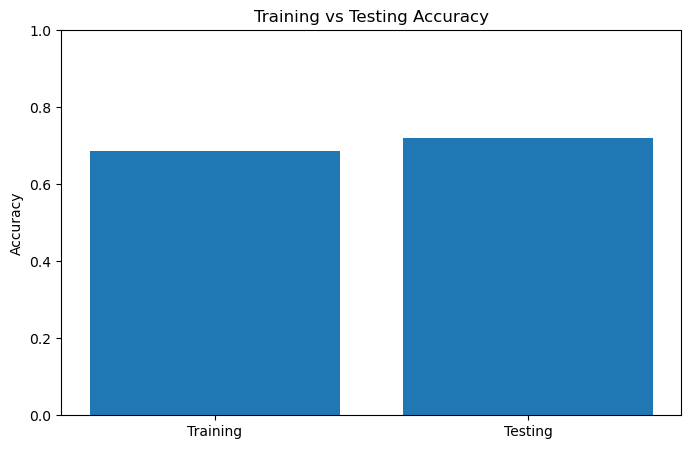

In [137]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Training", "Testing"],
    [train_accuracy, test_accuracy]
)

plt.title("Training vs Testing Accuracy")

plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.show()

In [138]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV Scores:", cv_scores)

print("Mean CV Accuracy:", cv_scores.mean())

CV Scores: [0.675   0.61875 0.6875  0.71875 0.61875]
Mean CV Accuracy: 0.6637500000000001


In [139]:
model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", LogisticRegression(
        C=0.1,
        max_iter=1000
    ))
])

In [140]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age',
                                                   'Symptom_Duration_Days',
                                                   'Temperature_C', 'Pulse_bpm',
                                                   'SpO2_percent',
                                                   'Systolic_BP']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Sex', 'Department',
                                                   'Arrival_Mode',
                                                   'Triage_Level',
                                                   'Known_Comorbidity'])])),
                ('classifier', LogisticRegression(C=0.1, max_iter=1000))])

In [141]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=8,
            random_state=42
        ))
    ])
}

In [142]:
results = []

for name, clf in models.items():

    clf.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train,
        clf.predict(X_train)
    )

    test_acc = accuracy_score(
        y_test,
        clf.predict(X_test)
    )

    results.append({
        "Model": name,
        "Training Accuracy": train_acc,
        "Testing Accuracy": test_acc
    })

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Training Accuracy  Testing Accuracy
0  Logistic Regression            0.68750             0.720
1        Decision Tree            0.75375             0.665
2        Random Forest            0.90000             0.670


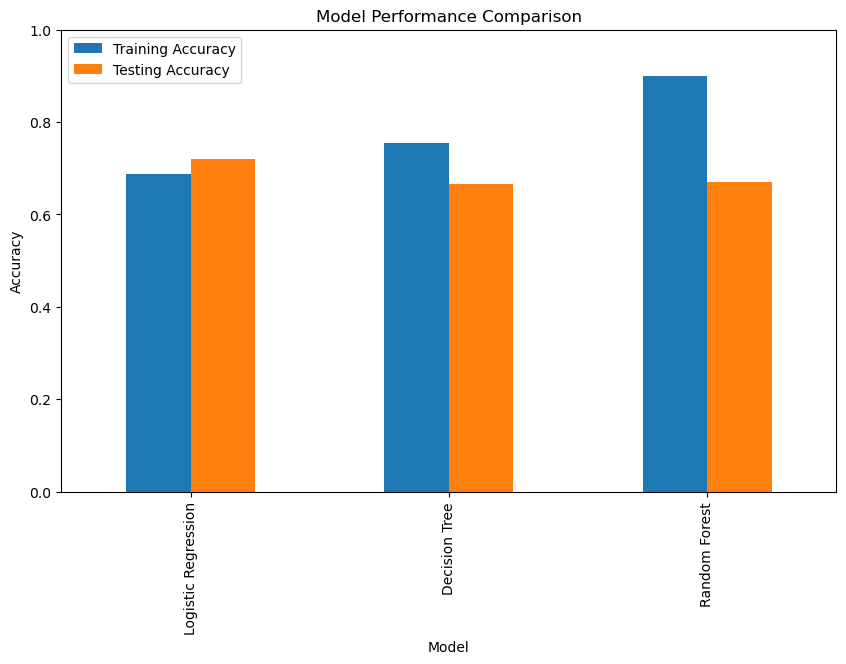

In [143]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")

plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.show()

In [144]:
rf = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

rf.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age',
                                                   'Symptom_Duration_Days',
                                                   'Temperature_C', 'Pulse_bpm',
                                                   'SpO2_percent',
                                                   'Systolic_BP']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Sex', 'Department',
                                                   'Arrival_Mode',
                                                   'Triage_Level',
                                                   'Known_Comorbidity'])])),
                ('classifier',
                 RandomForestClassifier(max_depth=5, min_samples_leaf=5,
                                        min_samples_split=10,
                                        random_state=42))])

In [145]:
rf_train_acc = accuracy_score(
    y_train,
    rf.predict(X_train)
)

rf_test_acc = accuracy_score(
    y_test,
    rf.predict(X_test)
)

print("RF Training Accuracy:", rf_train_acc)

print("RF Testing Accuracy:", rf_test_acc)

RF Training Accuracy: 0.73
RF Testing Accuracy: 0.705


In [146]:
joblib.dump(
    model,
    "patient_admission_model.pkl"
)

['patient_admission_model.pkl']

In [147]:
loaded_model = joblib.load(
    "patient_admission_model.pkl"
)

In [148]:
new_patient = pd.DataFrame({
    "Age": [45],
    "Sex": ["Male"],
    "Department": ["Emergency"],
    "Arrival_Mode": ["Referral"],
    "Triage_Level": ["Yellow"],
    "Symptom_Duration_Days": [3],
    "Temperature_C": [38.5],
    "Pulse_bpm": [110],
    "SpO2_percent": [95],
    "Systolic_BP": [110],
    "Known_Comorbidity": ["Yes"]
})

In [149]:
!pip install streamlit

In [ ]:
!streamlit run app.py